# Cinemática inversa: qué ángulos para llegar a un punto

**Taller de Proyecto I (E0306) — 2.º cuatrimestre 2026 — Grupo N.º 3**

---

## Alcance

La cinemática directa contesta **dónde queda el vaso** para cada juego de ángulos, y el
jacobiano, **cómo se mueve**. Este cuaderno contesta la inversa: **dado un punto, qué
ángulos**. Es el cálculo que hace falta para que el brazo vaya a una posición pedida en vez
de ser empujado eje por eje: automatizar la demostración, memorizar posiciones y volver a
ellas.

Resuelve cinco cosas:

1. La **solución cerrada**, que para este brazo existe y es corta.
2. Por qué **nunca hay que elegir entre las dos ramas** del codo, aunque la bibliografía
   diga que sí.
3. Qué limita el espacio alcanzable, punto por punto: el alcance, los topes o la caja.
4. La **redundancia**: la orientación de la pinza es un grado de libertad sobrante, y qué
   se puede hacer con él.
5. Qué le queda al firmware, incluido qué hacer cuando el punto pedido no existe.

> El vocabulario sigue el de la materia Introducción a la Robótica: **espacio de
> configuración** para el de los ángulos, **espacio de trabajo** para el de los puntos
> alcanzables, y **TCP** (*tool center point*) para el punto entre las mordazas, que acá se
> llama simplemente «la punta».

> **Cuatro decisiones de diseño enmarcan este cuaderno**, tomadas junto con el grupo:
> la inversa **se va a implementar** en el firmware, para ir a posiciones memorizadas y
> automatizar la demostración; si el punto no es alcanzable **se rechaza la orden**; la
> pinza va horizontal **mientras sostiene el vaso** y queda libre cuando está vacía; y la
> calibración del cero de cada eje se hará por ensayo, después del montaje.

Todo usa `math` y `numpy`. La verificación con el *Robotics Toolbox* es opcional.

In [1]:
import math

import numpy as np

L1, L2, L3 = 120.0, 120.0, 85.0          # mm
H_HOMBRO = 190.0                         # altura del hombro sobre la mesa
CAJA_H, R_GUARDA = 100.0, 113.0          # la caja base, y el radio de la guarda
Z_GARRA = 70.0                           # altura de la punta al agarrar
VENT = {'hombro': (50.0, 110.0), 'codo': (0.0, 120.0), 'muneca': (-108.0, 40.0)}

def articulaciones(q2, q3, q4):
    '''(r, z) de hombro, codo, muneca y punta. En radianes.'''
    a23, a234 = q2 + q3, q2 + q3 + q4
    co = (L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2))
    mu = (co[0] + L2*math.sin(a23), co[1] + L2*math.cos(a23))
    return [(0.0, H_HOMBRO), co, mu, (mu[0] + L3*math.sin(a234),
                                      mu[1] + L3*math.cos(a234))]

def libre(q2, q3, q4):
    '''La guarda: nada bajo la tapa dentro del radio de esquina, y nada bajo la mesa.'''
    return all(z >= 0 and not (z < CAJA_H and abs(r) < R_GUARDA)
               for r, z in articulaciones(q2, q3, q4))

---

# 1. Tres desacoples y el problema queda en un triángulo

La cinemática inversa de un brazo cualquiera es un sistema de ecuaciones trascendentes que
en general **no tiene solución cerrada**. Que acá la tenga no es suerte: es la misma
estructura que simplificó la directa —tres ejes paralelos y uno perpendicular— leída al
revés. El problema se parte en tres pasos, y cada uno saca una variable.

**Primero la base.** Del punto pedido salen el giro y el radio:

$$q_1 = \mathrm{atan2}(y,\,x) \qquad r = \sqrt{x^2+y^2}$$

La bibliografía avisa de una ambigüedad: se podría girar la base 180° y alcanzar el punto
«de espaldas», con radio negativo. **Este brazo no puede**: el hombro arranca en 50° desde
la vertical, siempre inclinado hacia adelante, así que el radio es siempre positivo y la
base no aporta ambigüedad. Queda un problema plano en `(r, z)`.

**Segundo, la pinza.** Si se decide con qué orientación `α` llega la pinza, la muñeca queda
determinada —es el *desacople de muñeca*, en su versión más simple—:

$$r_m = r - L_3\,\mathrm{sen}\,\alpha \qquad z_m = z - L_3\cos\alpha$$

Con la pinza horizontal esto es, literalmente, restarle 85 mm al radio.

**Tercero, los dos eslabones.** Del hombro a la muñeca hay una distancia `d`, y con los dos
eslabones forma un triángulo. Como **L1 = L2** el triángulo es isósceles, y eso evita la ley
del coseno: alcanza con mirar media altura, que es un triángulo rectángulo.

$$d = \sqrt{r_m^2 + (z_m - Z_0)^2} \qquad
\mathrm{semi} = \arccos\frac{d}{L_1+L_2} \qquad
\mathrm{medio} = \mathrm{atan2}(r_m,\, z_m - Z_0)$$

$$q_2 = \mathrm{medio} \mp \mathrm{semi} \qquad q_3 = \pm\,2\,\mathrm{semi}
\qquad q_4 = \alpha - q_2 - q_3$$

El `arccos` hace de test de alcance: si `d > 240 mm` el argumento se pasa de 1 y no hay
solución. Y el `±` son las **dos ramas**, codo abajo y codo arriba.

Que haya puntos sin solución no es un defecto del método sino la naturaleza del problema:
*cualquier punto del espacio de configuración se puede mapear al espacio de trabajo, pero lo
inverso no es necesariamente cierto*. Por eso la decisión de **rechazar** la orden en vez de
inventar una respuesta ([ADR-011](ADR-011-cinematica-inversa-cerrada)) no es sólo una
convención de diseño: es lo único que se puede hacer sin mentir.

In [2]:
def inversa(x, y, z, alfa=90.0, verboso=False):
    '''Angulos [grados] para poner la punta en (x, y, z) con la pinza a alfa.

    Devuelve (q1, q2, q3, q4) o None. Con verboso=True devuelve ademas el motivo
    del rechazo, que es lo que el firmware necesita para avisar por que no va.'''
    q1 = math.degrees(math.atan2(y, x))
    r = math.hypot(x, y)
    a = math.radians(alfa)
    rm, zm = r - L3*math.sin(a), z - L3*math.cos(a)          # la muneca
    d = math.hypot(rm, zm - H_HOMBRO)
    if d > L1 + L2:
        return (None, 'fuera de alcance') if verboso else None

    semi = math.acos(min(1.0, d/(L1 + L2)))                  # L1 = L2: isosceles
    medio = math.atan2(rm, zm - H_HOMBRO)
    motivos = []
    for s in (1, -1):                                        # codo abajo y codo arriba
        q2, q3 = medio - s*semi, 2*s*semi
        q4 = a - q2 - q3
        g = [math.degrees(v) for v in (q2, q3, q4)]
        fuera = [k for k, v in zip(('hombro', 'codo', 'muneca'), g)
                 if not VENT[k][0] <= v <= VENT[k][1]]
        if fuera:
            motivos.append('fuera de ventana: ' + ', '.join(fuera))
            continue
        if not libre(q2, q3, q4):
            motivos.append('el brazo chocaria la caja')
            continue
        sol = (q1, g[0], g[1], g[2])
        return (sol, 'ok') if verboso else sol
    return (None, ' / '.join(motivos)) if verboso else None

# control rapido: la pose de agarre del cuaderno de cinematica directa
print(inversa(250*math.cos(math.radians(35)), 250*math.sin(math.radians(35)), Z_GARRA))

(35.0, 94.2490404636687, 63.55666584286981, -67.80570630653851)


---

# 2. La simplificación del isósceles no es un atajo dudoso

La forma general para dos eslabones cualesquiera es la ley del coseno:

$$\cos q_3 = \frac{d^2 - L_1^2 - L_2^2}{2L_1L_2}$$

Con `L1 = L2 = L` queda `cos q3 = d²/(2L²) − 1`, que por la identidad del ángulo mitad es
exactamente `q3 = 2·arccos(d/2L)`. Las dos formas dan lo mismo, y conviene mostrarlo en vez
de afirmarlo, porque si alguna vez los eslabones dejan de ser iguales hay que volver a la
general.

In [3]:
def codo_general(d):
    '''Ley del coseno, que vale para cualquier par de eslabones.'''
    c = (d*d - L1*L1 - L2*L2)/(2*L1*L2)
    return math.degrees(math.acos(max(-1.0, min(1.0, c))))

def codo_isosceles(d):
    '''La simplificacion que usa este cuaderno, valida solo con L1 = L2.'''
    return math.degrees(2*math.acos(min(1.0, d/(L1 + L2))))

peor = max(abs(codo_general(d) - codo_isosceles(d)) for d in np.arange(1.0, 240.0, 0.5))
print(f"ley del coseno contra el isosceles: {peor:.1e} grados de diferencia")

ley del coseno contra el isosceles: 1.7e-13 grados de diferencia


---

# 3. Nunca hay que elegir rama

Todo manual de robótica dice que la inversa de un brazo plano tiene dos soluciones y que
hay que elegir una, normalmente «codo arriba» o «codo abajo». Acá **la elección ya está
hecha por el tope mecánico**: la ventana del codo va de 0° a 120°, y la rama de codo arriba
necesita `q3 < 0`. Vale la pena verificarlo sobre todo el plano, no sobre un punto.

In [4]:
def ramas(r, z, alfa=90.0):
    '''Las dos soluciones geometricas, con su estado. Para contarlas.'''
    a = math.radians(alfa)
    rm, zm = r - L3*math.sin(a), z - L3*math.cos(a)
    d = math.hypot(rm, zm - H_HOMBRO)
    if d > L1 + L2 or d < 1e-9:
        return []
    semi, medio = math.acos(min(1.0, d/(L1 + L2))), math.atan2(rm, zm - H_HOMBRO)
    out = []
    for s in (1, -1):
        q2, q3 = medio - s*semi, 2*s*semi
        q4 = a - q2 - q3
        g = [math.degrees(v) for v in (q2, q3, q4)]
        dentro = all(VENT[k][0] <= v <= VENT[k][1]
                     for k, v in zip(('hombro', 'codo', 'muneca'), g))
        out.append({'rama': 'codo abajo' if s > 0 else 'codo arriba', 'g': g,
                    'util': dentro and libre(q2, q3, q4)})
    return out

cuenta = {0: 0, 1: 0, 2: 0}
for ri in np.arange(0.0, 340.0, 2.0):
    for zi in np.arange(0.0, 400.0, 2.0):
        rr = ramas(float(ri), float(zi))
        if rr:
            cuenta[sum(1 for x in rr if x['util'])] += 1
total = sum(cuenta.values())
print(f"puntos con solucion geometrica: {total}")
for n in (0, 1, 2):
    print(f"  con {n} solucion(es) util(es): {cuenta[n]:6d}   {100*cuenta[n]/total:5.1f} %")

print(f"\n{'r':>6}{'rama':>14}{'hombro':>9}{'codo':>8}{'muneca':>9}")
for r in (210.0, 250.0, 288.0):
    for x in ramas(r, Z_GARRA):
        print(f"{r:>6.0f}{x['rama']:>14}{x['g'][0]:>9.1f}{x['g'][1]:>8.1f}"
              f"{x['g'][2]:>9.1f}   {'UTIL' if x['util'] else 'descartada'}")

puntos con solucion geometrica: 29390
  con 0 solucion(es) util(es):  24815    84.4 %
  con 1 solucion(es) util(es):   4575    15.6 %
  con 2 solucion(es) util(es):      0     0.0 %

     r          rama   hombro    codo   muneca
   210    codo abajo     90.0    87.6    -87.6   UTIL
   210   codo arriba    177.6   -87.6     -0.0   descartada
   250    codo abajo     94.2    63.6    -67.8   UTIL
   250   codo arriba    157.8   -63.6     -4.2   descartada
   288    codo abajo    109.9    21.4    -41.3   UTIL
   288   codo arriba    131.3   -21.4    -19.9   descartada


**Cero puntos con dos soluciones.** La rama de codo arriba pediría, a r = 250, un hombro a
157,8°, que son 48° más allá del tope. O sea que la inversa de este brazo es **una función**:
para cada punto alcanzable hay un solo juego de ángulos, y el firmware **no necesita lógica
de selección de rama**. Es una consecuencia directa de la ventana de
[ADR-010](ADR-010-ventanas-de-recorrido) que no habíamos notado al elegirla.

---

# 4. Qué limita el espacio alcanzable

Con la pinza horizontal, el conjunto de puntos a los que llega la punta tiene cuatro
fronteras distintas, y conviene saber cuál manda en cada lugar: no es lo mismo que al brazo
le falte largo a que le falte recorrido.

In [5]:
def estado(r, z, alfa=90.0):
    '''0 util, 1 choca la caja, 2 fuera de ventana, 3 fuera de alcance.'''
    rr = ramas(r, z, alfa)
    if not rr:
        return 3
    if any(x['util'] for x in rr):
        return 0
    for x in rr:
        g = x['g']
        if all(VENT[k][0] <= v <= VENT[k][1]
               for k, v in zip(('hombro', 'codo', 'muneca'), g)):
            return 1
    return 2

NOMBRE = {0: 'alcanzable', 1: 'chocaria la caja', 2: 'fuera de ventana',
          3: 'fuera de alcance'}
print("a la altura de agarre, borde por borde:")
for r in (197.0, 198.0, 199.0, 287.0, 288.0, 289.0, 294.0, 296.0):
    print(f"  r = {r:>5.0f} mm : {NOMBRE[estado(r, Z_GARRA)]}")

util = [r for r in np.arange(150.0, 320.0, 0.5) if estado(float(r), Z_GARRA) == 0]
print(f"\nbanda util a z = 70: {min(util):.0f} a {max(util):.0f} mm")
print(f"  el borde interior lo fija la caja; el exterior, el tope del hombro")
print(f"  geometricamente el brazo llegaria a "
      f"{max(r for r in np.arange(150.0, 340.0, 0.5) if estado(float(r), Z_GARRA) != 3):.0f} mm")

a la altura de agarre, borde por borde:
  r =   197 mm : chocaria la caja
  r =   198 mm : chocaria la caja
  r =   199 mm : alcanzable
  r =   287 mm : alcanzable
  r =   288 mm : alcanzable
  r =   289 mm : fuera de ventana
  r =   294 mm : fuera de alcance
  r =   296 mm : fuera de alcance

banda util a z = 70: 198 a 288 mm
  el borde interior lo fija la caja; el exterior, el tope del hombro
  geometricamente el brazo llegaria a 292 mm


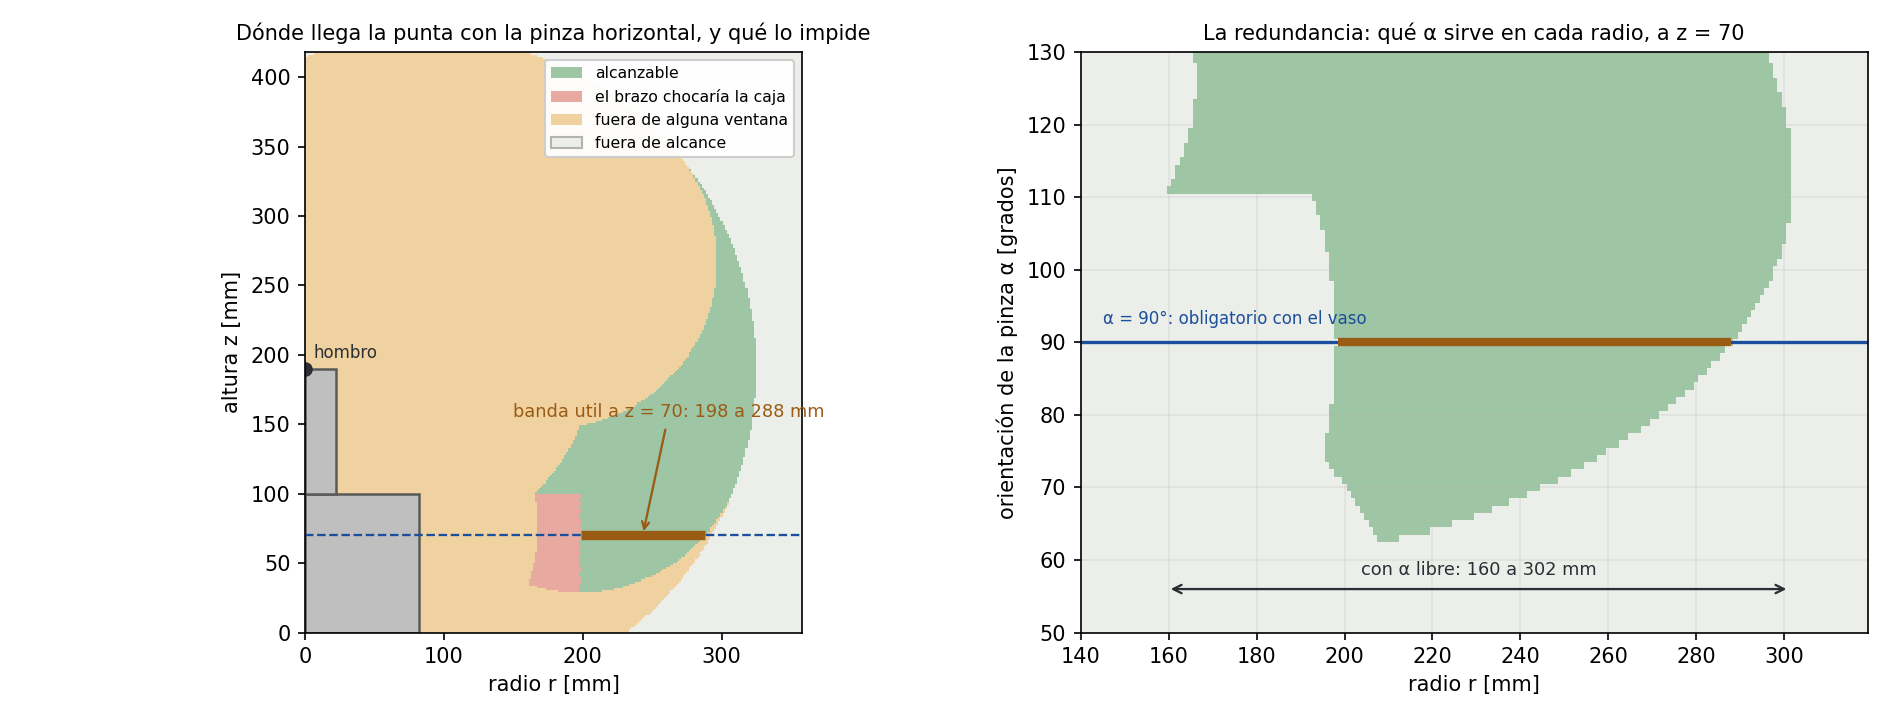

El mapa dice algo que no se ve en una tabla de números: **ninguno de los dos bordes de la
banda útil es el alcance del brazo**. El interior lo pone la caja —el brazo chocaría su
propia base— y el exterior, el tope del hombro: a 289 mm el hombro ya pediría 110,9° contra
un tope de 110°, mientras que geométricamente la punta llegaría a

$$\sqrt{(L_1+L_2)^2 - (Z_0 - z)^2} + L_3 = \sqrt{240^2 - 120^2} + 85 = 292{,}8\ \mathrm{mm}$$

Los últimos 5 mm los come el recorrido, no el eslabón.

---

# 5. Verificación

Dos controles. El primero es el que importa: **componer la inversa con la directa tiene que
devolver el punto de partida**, en todo el conjunto alcanzable. El segundo cruza contra el
*Robotics Toolbox* de Peter Corke, que resuelve la inversa por un método numérico iterativo,
completamente distinto del cerrado.

In [6]:
def directa(q1, q2, q3, q4):
    '''La formula del firmware, en grados.'''
    q1, q2, q3, q4 = (math.radians(v) for v in (q1, q2, q3, q4))
    a2, a23, a234 = q2, q2 + q3, q2 + q3 + q4
    r = L1*math.sin(a2) + L2*math.sin(a23) + L3*math.sin(a234)
    z = H_HOMBRO + L1*math.cos(a2) + L2*math.cos(a23) + L3*math.cos(a234)
    return r*math.cos(q1), r*math.sin(q1), z

rng = np.random.default_rng(17)
peor, n = 0.0, 0
while n < 5000:
    q1 = rng.uniform(-180.0, 180.0)
    r, z = rng.uniform(150.0, 320.0), rng.uniform(0.0, 350.0)
    sol = inversa(r*math.cos(math.radians(q1)), r*math.sin(math.radians(q1)), z)
    if sol is None:
        continue
    n += 1
    p = directa(*sol)
    peor = max(peor, max(abs(p[0] - r*math.cos(math.radians(q1))),
                         abs(p[1] - r*math.sin(math.radians(q1))), abs(p[2] - z)))
print(f"directa(inversa(punto)) contra el punto, {n} puntos alcanzables al azar")
print(f"  error maximo: {peor:.1e} mm")

directa(inversa(punto)) contra el punto, 5000 puntos alcanzables al azar
  error maximo: 1.7e-13 mm


In [7]:
try:
    import roboticstoolbox as rtb
    brazo = rtb.DHRobot([
        rtb.RevoluteDH(d=H_HOMBRO, a=0.0, alpha=-math.pi/2),
        rtb.RevoluteDH(a=L1, offset=-math.pi/2),
        rtb.RevoluteDH(a=L2),
        rtb.RevoluteDH(a=L3)])
    print(f"{'punto':>22}{'cerrada (q2,q3,q4)':>30}{'numerica del toolbox':>30}")
    for r, z in ((210.0, Z_GARRA), (250.0, Z_GARRA), (288.0, Z_GARRA), (250.0, 170.0)):
        g = inversa(r, 0.0, z)
        T = brazo.fkine(np.radians(g))                   # la pose que pide ese punto
        s = brazo.ikine_LM(T, q0=np.radians(g)*0.7, mask=[1, 1, 1, 0, 1, 0])
        num = np.degrees(s.q)[1:] if s.success else None
        print(f"  r={r:>5.0f} z={z:>5.0f}"
              f"{f'{g[1]:8.2f}{g[2]:8.2f}{g[3]:8.2f}':>30}"
              f"{f'{num[0]:8.2f}{num[1]:8.2f}{num[2]:8.2f}' if num is not None else 'no converge':>30}")
    print("\nEl metodo numerico llega a la misma solucion, iterando; el cerrado la da")
    print("en una cuenta, sin punto de partida y sin riesgo de no converger.")
except ImportError:
    print("Robotics Toolbox no instalado: cruce omitido")
    print("  instalarlo con: pip install roboticstoolbox-python")

                 punto            cerrada (q2,q3,q4)          numerica del toolbox
  r=  210 z=   70         90.05   87.56  -87.61         90.05   87.56  -87.61
  r=  250 z=   70         94.25   63.56  -67.81         94.25   63.56  -67.81
  r=  288 z=   70        109.87   21.43  -41.30        109.87   21.43  -41.30
  r=  250 z=  170         50.74   92.34  -53.08         50.74   92.34  -53.08

El metodo numerico llega a la misma solucion, iterando; el cerrado la da
en una cuenta, sin punto de partida y sin riesgo de no converger.


---

# 6. Sub-actuado y, a la vez, redundante

Acá hay que ser preciso con el vocabulario, porque las dos palabras que describen a este
brazo parecen contradecirse y no lo hacen: valen en espacios distintos.

**El brazo es sub-actuado.** Imponer una pose completa en el espacio son seis componentes
—tres de posición y tres de orientación— y el brazo tiene cuatro articulaciones. Con menos de
seis grados de libertad el sistema está sub-actuado, y la receta estándar es **llevar el
problema a forma cuadrada eliminando filas**: aceptar que algunos grados de libertad
cartesianos no son controlables, y renunciar a ellos explícitamente.

Eso es exactamente lo que hace este cuaderno, aunque no lo dijera. Controla `x`, `y`, `z` y
**una** componente de orientación, el ángulo `α` de la pinza en el plano del brazo, y
renuncia a las otras dos: la pinza no puede inclinarse hacia los costados ni girar sobre su
propio eje, y no hace falta que pueda. En el cuaderno del jacobiano esa renuncia está escrita
en código, en la verificación contra el toolbox: `mask=[1, 1, 1, 0, 1, 0]` es la lista de qué
filas se conservan.

**Y a la vez es redundante para la tarea que tiene.** Fijado lo anterior quedan tres
articulaciones en el plano para dos coordenadas, `(r, z)`: sobra una, y lo que sobra es la
orientación `α`. Hasta acá la fijamos en 90° sin discutirlo, y conviene decir de dónde sale
esa decisión y cuánto cuesta.

Sale de la tarea: **mientras la pinza sostiene el vaso, `α` tiene que ser 90°**, o el
líquido se derrama. No es una conveniencia de cálculo, es el requerimiento. Pero **con la
pinza vacía la orientación queda libre**, y entonces el grado de libertad sobrante se puede
usar: para llegar más lejos, para acercarse más, o para quedarse lejos de los topes.

In [8]:
ALFAS = np.arange(50.0, 131.0, 1.0)
libres = [r for r in np.arange(150.0, 320.0, 0.5)
          if any(estado(float(r), Z_GARRA, float(a)) == 0 for a in ALFAS)]
print(f"banda a z = 70 con la pinza horizontal : {min(util):.0f} a {max(util):.0f} mm"
      f"  ({max(util)-min(util):.0f} mm)")
print(f"banda a z = 70 con la pinza libre      : {min(libres):.0f} a {max(libres):.0f} mm"
      f"  ({max(libres)-min(libres):.0f} mm)")

def margen(g):
    '''Cuanto le sobra al eje mas comprometido, en grados.'''
    return min(min(v - VENT[k][0], VENT[k][1] - v)
               for k, v in zip(('hombro', 'codo', 'muneca'), g[1:]))

def alfa_comoda(r, z):
    '''Con la pinza vacia: la orientacion que deja mas margen a los topes.'''
    mejor = None
    for a in ALFAS:
        sol = inversa(r, 0.0, z, float(a))
        if sol and (mejor is None or margen(sol) > mejor[1]):
            mejor = (float(a), margen(sol))
    return mejor

print(f"\n{'punto':>16}{'alfa comoda':>14}{'margen':>10}{'margen con alfa=90':>22}")
for r, z in ((200.0, Z_GARRA), (250.0, Z_GARRA), (288.0, Z_GARRA), (170.0, Z_GARRA)):
    mejor = alfa_comoda(r, z)
    base = inversa(r, 0.0, z)
    print(f"  r={r:>5.0f} z={z:>4.0f}"
          f"{mejor[0]:>13.0f}°{mejor[1]:>9.1f}°"
          f"{(f'{margen(base):.1f}°' if base else 'sin solucion'):>22}")

banda a z = 70 con la pinza horizontal : 198 a 288 mm  (90 mm)
banda a z = 70 con la pinza libre      : 160 a 302 mm  (142 mm)

           punto   alfa comoda    margen    margen con alfa=90
  r=  200 z=  70           97°     23.1°                 15.6°
  r=  250 z=  70          113°     29.9°                 15.8°
  r=  288 z=  70          125°     18.8°                  0.1°
  r=  170 z=  70          111°      4.1°          sin solucion


Fijar la pinza horizontal cuesta **52 mm de banda útil**: de 142 mm posibles quedan 90. Es
un costo que la tarea impone y que conviene tener escrito, porque convierte una hipótesis que
parecía arbitraria en una restricción con causa y con precio.

Con la pinza vacía, en cambio, el criterio razonable es **la orientación que deja más margen
a los topes**: mantiene al brazo lejos de las posiciones donde un error de calibración lo
hace chocar contra un límite. En el extremo exterior esa orientación ya no es 90°, y en
r = 170 mm —donde con la pinza horizontal no hay solución— aparece una.

Hay una consecuencia práctica que el firmware tiene que respetar: **antes de cerrar la pinza
sobre el vaso hay que volver a `α = 90°`**. La libertad es sólo para moverse vacío.

---

# 7. Cerca del borde, la inversa se endurece

Un punto que el mapa no muestra: no todos los puntos alcanzables se alcanzan con la misma
precisión. Cuanto más estirado el brazo, más grados de codo hacen falta por milímetro de
punta, que es el mismo fenómeno que el número de condición del jacobiano, dicho en unidades
que se entienden solas.

In [9]:
print(f"{'radio':>8}{'codo':>9}{'mm de punta por grado de codo':>32}"
      f"{'grados por mm':>18}")
for r in (210.0, 250.0, 270.0, 285.0, 288.0):
    a, b = inversa(r - 1.0, 0.0, Z_GARRA), inversa(r, 0.0, Z_GARRA)
    if a and b:
        porgrado = 1.0/abs(b[2] - a[2])
        print(f"{r:>8.0f}{b[2]:>9.1f}{porgrado:>28.2f} mm{1/porgrado:>15.2f}")

   radio     codo   mm de punta por grado de codo     grados por mm
     210     87.6                        2.02 mm           0.50
     250     63.6                        1.37 mm           0.73
     270     46.5                        1.00 mm           1.00
     285     27.3                        0.59 mm           1.68
     288     21.4                        0.47 mm           2.11


En el borde exterior hacen falta **más de 2 grados de codo por milímetro**, contra 0,7 en el
medio de la banda. Lo que está apareciendo ahí tiene nombre propio: es la **singularidad de
codo**, la configuración en la que el centro de la muñeca y los centros de rotación del
hombro y del codo quedan alineados. El brazo se acerca a ella al estirarse, y el
[jacobiano](Jacobiano) la mide por el otro lado, con el determinante y el número de
condición. La consecuencia es de calibración, no de cálculo: la inversa es exacta,
pero ahí el error de posición que produce el juego de los engranajes se multiplica. Para
trabajo fino conviene quedarse en el medio de la banda, o mover el hombro en vez del codo.

---

# 8. Lo que le queda al firmware

La inversa **sí va a implementarse**: habilita ir a una posición memorizada y automatizar la
demostración. El algoritmo completo son unas doce líneas, sin iteraciones, sin punto de
partida y sin librerías: dos `atan2`, un `acos`, una raíz y cuatro comparaciones.

| Requerimiento | Valor |
|---|---|
| Entrada | punto `(x, y, z)` y orientación de pinza `α` |
| Salida | `(q1, q2, q3, q4)` o **rechazo** con motivo |
| Ramas a evaluar | las dos; una siempre cae fuera de ventana, no hay que elegir |
| Si el punto no es alcanzable | **se rechaza la orden** y el brazo se queda donde está |
| `α` con el vaso tomado | fija en 90°, sin excepción |
| `α` con la pinza vacía | libre; criterio sugerido, la que deja más margen a los topes |
| Antes de cerrar la pinza | volver a `α = 90°` |
| Costo de cómputo | una sola pasada, acotada: sirve dentro del lazo de control |

**Rechazar y no saturar** es coherente con lo que ya hace la guarda con los incrementos del
joystick, y evita que el brazo «se deslice» por un borde que tiene forma irregular: parte lo
fija la caja y parte el tope del hombro.

Sobre **memorizar posiciones**, que es una de las funciones que motivan esta implementación,
la recomendación desde la cinemática —la decisión es de la parte de firmware— es **guardar
los ángulos de articulación y no las coordenadas**: reproducir una posición guardada no
necesita entonces inversa, no puede fallar por alcance, y no arrastra el error del modelo. La
inversa sirve para **calcular** un destino a partir de un punto deseado; una vez calculado,
lo que se guarda es el resultado.

---

# 9. De los puntos al movimiento: camino y trayectoria

Este cuaderno resuelve **puntos sueltos**, y conviene no confundir eso con resolver el
movimiento. La distinción es la que usa la bibliografía:

- **Camino**: la secuencia de puntos a recorrer, en orden. Es lo que da la inversa aplicada a
  una lista de destinos.
- **Trayectoria**: el mismo camino, pero **con marca temporal** en cada punto. Y se le exige
  ser *suave*: que las primeras derivadas —velocidad, aceleración, y ojalá el tirón— sean
  continuas.

La suavidad no es un lujo estético, y acá se ve por qué: **el dimensionamiento del brazo
supone movimiento cuasi-estático**, con un tope de aceleración de la punta de 0,98 m/s² que
sale del criterio del 10 % para despreciar el término dinámico. Una interpolación lineal
entre dos ángulos tiene velocidad discontinua en los extremos, o sea aceleración infinita en
el papel y un tirón en la práctica: viola el supuesto sobre el que está calculado todo el par.

La herramienta estándar es el **polinomio de quinto orden**, que con velocidad y aceleración
nulas en los dos extremos queda `s(τ) = 10τ³ − 15τ⁴ + 6τ⁵`, con `τ = t/T`. Sus picos salen de
la forma, no del recorrido:

$$v_{max} = 1{,}875\,rac{\Delta}{T} \qquad a_{max} = 5{,}77\,rac{\Delta}{T^{2}}$$

Lo que esto le impone al firmware es un **tiempo mínimo por tramo**.

In [10]:
A_TOPE = 980.0             # mm/s2: el tope de aceleracion del dimensionamiento
K_V, K_A = 1.875, 5.7735   # picos del polinomio de quinto orden, por unidad

def tiempo_minimo(recorrido):
    '''Duracion minima de un tramo para no pasarse del tope de aceleracion.'''
    return math.sqrt(K_A*recorrido/A_TOPE)

print(f"{'tramo':>34}{'minimo':>11}{'si dura 2,0 s':>18}")
for nom, mm in (('traslado de 200 mm', 200.0),
                ('bajar 100 mm hasta el vaso', 100.0),
                ('recorrido radial completo, 90 mm', 90.0)):
    print(f"{nom:>34}{tiempo_minimo(mm):>9.2f} s{K_A*mm/2.0**2:>14.0f} mm/s2")

pico = K_A*200.0/2.0**2
print(f"\nla tarea del cuaderno de cinematica directa gira la base en 2,0 s:")
print(f"  pico de aceleracion {pico:.0f} mm/s2 contra el tope de {A_TOPE:.0f}:"
      f" margen de {A_TOPE/pico:.1f} veces")

                             tramo     minimo     si dura 2,0 s
                traslado de 200 mm     1.09 s           289 mm/s2
        bajar 100 mm hasta el vaso     0.77 s           144 mm/s2
  recorrido radial completo, 90 mm     0.73 s           130 mm/s2

la tarea del cuaderno de cinematica directa gira la base en 2,0 s:
  pico de aceleracion 289 mm/s2 contra el tope de 980: margen de 3.4 veces


O sea que **la secuencia que ya animamos respeta el supuesto del dimensionamiento con un
margen de 3,4 veces**, y queda una regla corta para el firmware: ningún tramo de 200 mm en
menos de 1,1 segundos. La trayectoria completa —interpolar en el espacio de articulaciones
con este perfil, que por construcción no puede salirse de las ventanas— es el paso que sigue,
y no es de este cuaderno.

---

# 10. Lo que falta

1. **La calibración del cero de cada eje**, que es lo que convierte estos ángulos en anchos
   de pulso y lo que de verdad va a fijar la precisión del brazo.
2. **La trayectoria completa de la tarea**, con el perfil de la sección 9 aplicado tramo por
   tramo y verificado contra el tope de velocidad de cada servomotor, que no son iguales entre
   sí.
3. **Medir el juego de los engranajes**, que es el que define cuánto vale realmente la
   precisión cerca del borde exterior.
4. **La interferencia del brazo consigo mismo**, que sigue pendiente del modelado 3D: la
   guarda de este cuaderno sólo mira la caja y la mesa.